# Co-Designed Fingertips for Tool Use

In this notebook, we introduce **NeroGrasp-Tools**, where a Nero arm with a parallel gripper must open and lift an articulated tool (`Carabiner` and `WireCutters`), and look at two agents from **codesign-baselines** whose fingertips were co-designed together with their control policy.

Estimated running time: ~4 min on a laptop CPU.

## 1. Setup

Make sure you run https://github.com/camral/codesign-gym/tree/main#basic-install and installed `codesign-baselines` (Section 1 of `morphhand_tutorial.ipynb`) beforehand.

First, let's install the NeroTools-specific requirements:


In [ ]:
# from directory containing codesign-gym
cd codesign-gym

# uv
uv pip install -r nerotools-requirements.txt --no-sources

# venv
python -m pip install -r nerotools-requirements.txt

# conda
python -m pip install -r nerotools-requirements.txt

Let's check our setup and load both agents:

In [ ]:
import os
import sys
from pathlib import Path

# Configure offscreen GL on macOS *before* importing mujoco / codesign_gym.
if sys.platform == "darwin":
    os.environ.setdefault("MUJOCO_GL", "cgl")

sys.path.insert(0, str(Path("helpers").resolve()))  # tutorial helper modules live in notebooks/helpers

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image as ShowImage, display
from matplotlib import colors
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from PIL import Image, ImageDraw, ImageFont

from nerotools_bundle import deform, load_bundle, load_tools_policy, make_tools_env, precomputed_decompositions, rollout

DEVICE = "cpu"  # every rollout in this notebook runs on the CPU
SEED = 4
np.random.seed(SEED)
torch.manual_seed(SEED)

RUNS_DIR = Path("runs")
CKPT_DIR = Path("nerotools_checkpoint_data")
RUNS_DIR.mkdir(exist_ok=True)

TOOLS = {"carabiner": "Carabiner", "wirecutters": "Wire cutters"}
bundles = {tool: load_bundle(CKPT_DIR, tool) for tool in TOOLS}
policies = {tool: load_tools_policy(bundle.checkpoint, DEVICE)[1] for tool, bundle in bundles.items()}

print(f"Platform: {sys.platform} | Device: {DEVICE}")
for tool, bundle in bundles.items():
    print(f"{TOOLS[tool]:12s} env: {bundle.env_id} | design dim: {bundle.theta.size} | "
          f"stored fingertip meshes: {len(bundle.meshes)}")

Platform: linux | Device: cpu
Carabiner    env: NeroGrasp-Tools-Carabiner | design dim: 24 | stored fingertip meshes: 3
Wire cutters env: NeroGrasp-Tools-WireCutters | design dim: 24 | stored fingertip meshes: 3


Some display and plotting helpers for later:

In [2]:
def save_gif(frames, path, *, frame_every=2, control_dt=0.1, scale=1):
    # One palette per frame (fast octree) keeps the small, brightly coloured tools and convex parts.
    imgs = [Image.fromarray(f[::scale, ::scale] if scale > 1 else f).quantize(256, method=Image.Quantize.FASTOCTREE)
            for f in frames]
    imgs[0].save(path, save_all=True, append_images=imgs[1:],
                 duration=max(20, int(1000 * control_dt * frame_every)), loop=0)
    display(ShowImage(filename=str(path)))


def label_frame(frame, text, *, scale=1):
    img = Image.fromarray(frame[::scale, ::scale] if scale > 1 else frame)
    banner_h = 34 if scale == 1 else 26
    canvas = Image.new("RGB", (img.width, img.height + banner_h), (22, 26, 33))
    canvas.paste(img, (0, banner_h))
    font = ImageFont.load_default(size=16 if scale == 1 else 12)
    ImageDraw.Draw(canvas).text((10, 8 if scale == 1 else 6), text, fill=(245, 245, 245), font=font)
    return np.asarray(canvas)


def frame_tool(env, design, *, distance=0.32, elevation=-30.0, azimuth=45.0):
    # Point the render camera at the tool: reset once with `design` to place the tool, then aim at it.
    designs = design if isinstance(design, list) else [design] * env.num_embodiments
    env.reset(seed=SEED, embodiment=designs)
    env.render(env_idx=0)  # creates the camera
    env.camera.lookat[:] = env.initial_obj_pos[0].cpu().numpy() + [0.0, 0.0, 0.03]
    env.camera.distance, env.camera.elevation, env.camera.azimuth = distance, elevation, azimuth


# Fingertip frame: the mounting plate is the plane y = 10 mm, the tip grows along +y and z is the long side.
# We draw (z, x, y) so the tip points up; a cyclic axis permutation keeps the mesh from being mirrored.
PLOT_AXES = [2, 0, 1]


def moved_mm(mesh, base):
    # Per-vertex distance from the base fingertip, in mm.
    return np.linalg.norm(np.asarray(mesh.vertices) - np.asarray(base.vertices), axis=1) * 1000.0


def mesh_limits(meshes, pad_mm=0.5):
    # Shared axis limits (mm) so several fingertips are drawn at the same scale.
    points = np.concatenate([np.asarray(m.vertices) for m in meshes])[:, PLOT_AXES] * 1000.0
    return points.min(axis=0) - pad_mm, points.max(axis=0) + pad_mm


def plot_fingertip(ax, mesh, *, shift=None, vmax=5.0, limits=None, highlight=None, title=None, view=(22, -58)):
    # Draw a fingertip in mm, optionally coloured by per-vertex shift, with simple directional shading.
    v, f = np.asarray(mesh.vertices)[:, PLOT_AXES] * 1000.0, np.asarray(mesh.faces)
    tris = v[f]
    if shift is None:
        rgb = np.tile(colors.to_rgb("lightsteelblue"), (len(f), 1))
    else:
        rgb = plt.get_cmap("viridis")(colors.Normalize(0.0, vmax)(np.asarray(shift)[f].mean(axis=1)))[:, :3]
    normals = np.cross(tris[:, 1] - tris[:, 0], tris[:, 2] - tris[:, 0])
    normals /= np.maximum(np.linalg.norm(normals, axis=1, keepdims=True), 1e-12)
    light = np.array([-0.3, -0.6, 0.75]) / np.linalg.norm([-0.3, -0.6, 0.75])
    rgb = rgb * (0.5 + 0.5 * np.abs(normals @ light))[:, None]
    ax.add_collection3d(Poly3DCollection(tris, facecolors=rgb, edgecolors=(0, 0, 0, 0.15), linewidths=0.3))
    if highlight is not None:
        ax.scatter(*v[highlight].T, color="crimson", s=14, depthshade=False)
    lo, hi = (v.min(axis=0), v.max(axis=0)) if limits is None else limits
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]))
    ax.set_box_aspect(hi - lo, zoom=1.15)
    ax.view_init(*view)
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=9.5)

## 2. Meet the Gripper

NeroGrasp-Tools mounts a 2-jaw parallel gripper on a 7-DoF Nero arm. In each 10 s episode (100 steps of 0.1 s), the policy has to open the tool's joint, by pushing the **carabiner** gate in or squeezing the **wire cutters** shut, and then lift the tool:
- **Action (`Box(8)` in `[-1, 1]`):** 7 arm joint-target increments (up to 0.1 rad per step) and 1 gripper command (`-1` fully open, `+1` closed).
- **Observation:** an `actor` view (episode progress, 9 robot joint positions, both fingertip positions, and 12 tool keypoints at the start) and a privileged `critic` view that adds the tool's live pose, mass, keypoints, contact flag and joint angle.
- **Reward:** fingertips close to the tool + contact + articulation (while the two fingertips touch opposite parts of the tool) + height (once the joint is more than 20% open), with a +10 bonus if the tool is still held, open and more than 3 cm up at the end. A world stops earning reward if its fingertips stray too far from the tool.
- **Embodiment:** `{"left": Mesh, "right": Mesh}`, one watertight triangle mesh per fingertip. The first 12 vertices of each mesh bolt onto the gripper jaw and must stay fixed; the rest can move.

All worlds share one episode clock, and fingertips cannot change mid-episode. Let's build one world per tool and look at the spaces and both scenes:

[codesign-gym] make_vec('NeroGrasp-Tools-Carabiner', num_envs=1): instantiating
[codesign-gym] make_vec('NeroGrasp-Tools-Carabiner', num_envs=1): success
[codesign-gym] make_vec('NeroGrasp-Tools-WireCutters', num_envs=1): instantiating
[codesign-gym] make_vec('NeroGrasp-Tools-WireCutters', num_envs=1): success
Observation: {'actor': (52,), 'critic': (98,)} | Action: (8,)
Embodiment: MeshSpace({'left': (base_vertices=72, base_faces=140, mounting_vertices=12), 'right': (base_vertices=72, base_faces=140, mounting_vertices=12)}, sample_perturbation_m=0.0001)
Module envs.nerograsp.nerotools_env 918659d load on device 'cpu' took 0.44 ms  (cached)


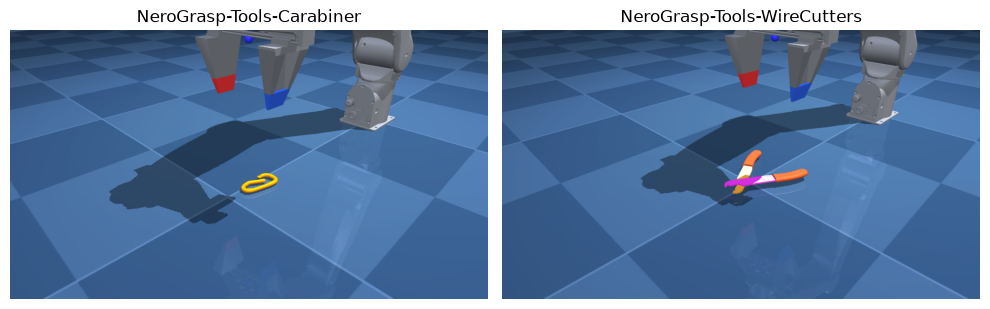

In [3]:
envs = {}
with precomputed_decompositions(*bundles.values()):
    for tool, bundle in bundles.items():
        envs[tool], _ = make_tools_env(bundle.env_id, 1, device=DEVICE, seed=SEED, render_mode="rgb_array", noise=False)

env = envs["carabiner"]
obs_shapes = {key: space.shape for key, space in env.single_observation_space.spaces.items()}
print("Observation:", obs_shapes, "| Action:", env.single_action_space.shape)
print("Embodiment:", env.embodiment_space)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (tool, tool_env) in zip(axes, envs.items()):
    frame_tool(tool_env, bundles[tool].base, distance=0.45)
    ax.imshow(tool_env.render(env_idx=0))
    ax.set_title(bundles[tool].env_id)
    ax.axis("off")
    tool_env.close()
plt.tight_layout()
plt.show()

Both tools start from the same base fingertip. Its 12 mounting vertices (red) form the patch that bolts onto the gripper jaw:

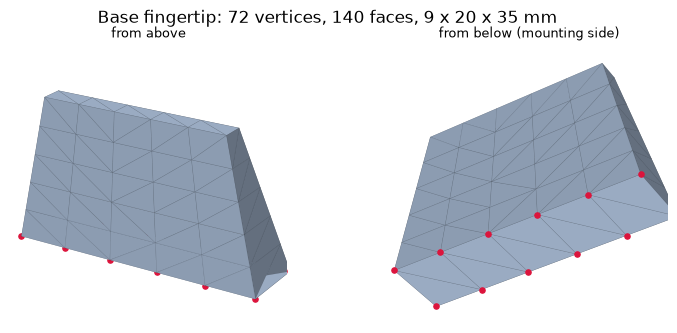

In [4]:
base_tip = bundles["carabiner"].base["left"]
n_mount = len(base_tip.vertices) - len(bundles["carabiner"].operators["left"])
size_mm = np.ptp(np.asarray(base_tip.vertices), axis=0) * 1000.0

fig = plt.figure(figsize=(9, 3.6))
for k, (view, label) in enumerate((((22, -58), "from above"), ((-40, -58), "from below (mounting side)"))):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    plot_fingertip(ax, base_tip, highlight=np.arange(n_mount), view=view, title=label)
fig.suptitle(f"Base fingertip: {len(base_tip.vertices)} vertices, {len(base_tip.faces)} faces, "
             f"{size_mm[0]:.0f} x {size_mm[1]:.0f} x {size_mm[2]:.0f} mm")
plt.show()

## 3. What Can a Fingertip Do?

Searching over raw vertices is high-dimensional and easily breaks the mesh, so the co-design runs deform each fingertip through a cage (**CBD-SA**, from [`structural-affinity`](https://camral.github.io/structural-affinity/)), compressed to its 4 dominant SVD modes. Each mode moves the replaceable vertices in a fixed pattern, and has an x, y and z coefficient bounded to ±5 mm:

`vertices[12:] += J @ D`, with `J` the `(60, 4)` mode matrix and `D` the `(4, 3)` coefficients.

Two fingertips × 4 modes × 3 axes give CMA-ES a **24-D** design vector, which is also appended to the policy's observation (scaled to `[-1, 1]`). Let's push each mode to +5 mm along each axis, coloured by how far each vertex moves:

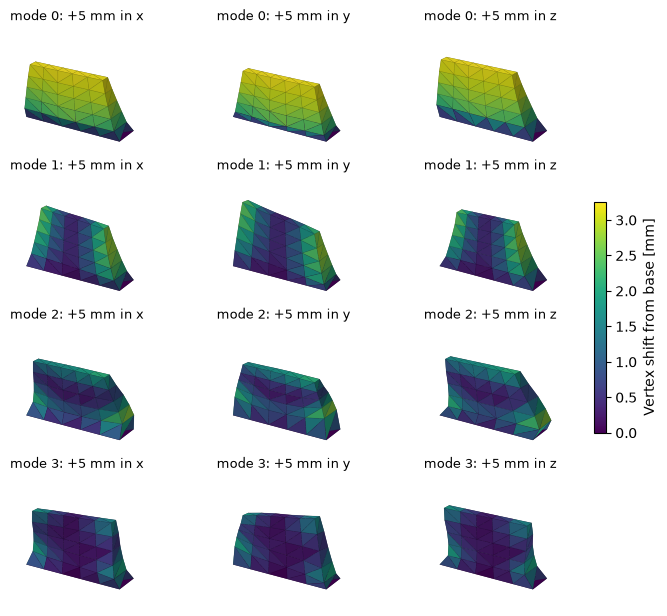

In [5]:
bundle = bundles["carabiner"]
J = bundle.operators["left"]
n_modes = J.shape[1]
mode_tips = {}
for mode in range(n_modes):
    for axis in range(3):
        D = np.zeros((n_modes, 3))
        D[mode, axis] = bundle.mesh_bound_m
        mode_tips[mode, axis] = deform(base_tip, J, D)

vmax = max(moved_mm(tip, base_tip).max() for tip in mode_tips.values())
limits = mesh_limits([base_tip, *mode_tips.values()])
fig = plt.figure(figsize=(10, 7.5))
for (mode, axis), tip in mode_tips.items():
    ax = fig.add_subplot(n_modes, 3, mode * 3 + axis + 1, projection="3d")
    plot_fingertip(ax, tip, shift=moved_mm(tip, base_tip), vmax=vmax, limits=limits,
                   title=f"mode {mode}: +5 mm in {'xyz'[axis]}")
fig.subplots_adjust(wspace=0.0, hspace=0.15)
fig.colorbar(plt.cm.ScalarMappable(colors.Normalize(0, vmax), "viridis"), ax=fig.axes, shrink=0.4,
             label="Vertex shift from base [mm]")
plt.show()

### What Did CMA-ES Pick?

Let's look at the two co-designed fingertip pairs, coloured by their distance from the base fingertip:

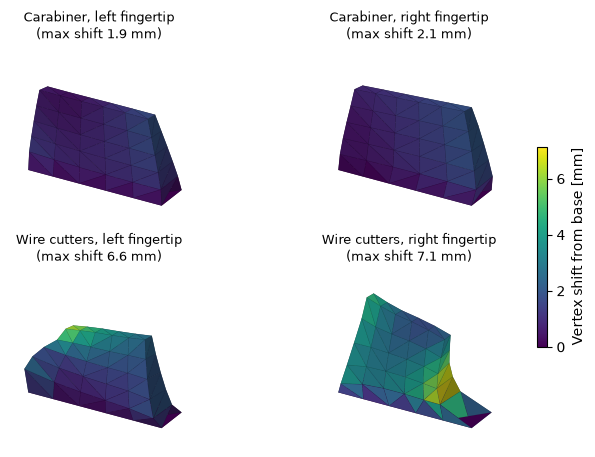

Carabiner    largest coefficient: 31% of the ±5 mm bound | coefficients above 50%: 0 of 24
Wire cutters largest coefficient: 97% of the ±5 mm bound | coefficients above 50%: 11 of 24


In [6]:
designs = {tool: bundle.design for tool, bundle in bundles.items()}
vmax = max(moved_mm(mesh, base_tip).max() for design in designs.values() for mesh in design.values())
limits = mesh_limits([mesh for design in designs.values() for mesh in design.values()])

fig = plt.figure(figsize=(10, 5.2))
for row, (tool, design) in enumerate(designs.items()):
    for col, side in enumerate(("left", "right")):
        shift = moved_mm(design[side], bundles[tool].base[side])
        ax = fig.add_subplot(2, 2, row * 2 + col + 1, projection="3d")
        plot_fingertip(ax, design[side], shift=shift, vmax=vmax, limits=limits,
                       title=f"{TOOLS[tool]}, {side} fingertip\n(max shift {shift.max():.1f} mm)")
fig.subplots_adjust(wspace=0.0, hspace=0.25)
fig.colorbar(plt.cm.ScalarMappable(colors.Normalize(0, vmax), "viridis"), ax=fig.axes, shrink=0.5,
             label="Vertex shift from base [mm]")
plt.show()

for tool, bundle in bundles.items():
    used = np.abs(bundle.theta) / bundle.mesh_bound_m
    print(f"{TOOLS[tool]:12s} largest coefficient: {used.max():.0%} of the ±5 mm bound | "
          f"coefficients above 50%: {(used > 0.5).sum()} of {used.size}")

---

## 4. The Co-Designed Agents in Action

Each checkpoint holds a FastTD3 policy trained jointly with CMA-ES over the fingertip design (Section 6). Let's roll out each agent with its own fingertips in a noise-free world (~30 s):

[codesign-gym] make_vec('NeroGrasp-Tools-Carabiner', num_envs=1): instantiating
[codesign-gym] make_vec('NeroGrasp-Tools-Carabiner', num_envs=1): success
Module mujoco_warp._src.derivative 2ae6b19 load on device 'cpu' took 0.57 ms  (cached)
Module _next_time_builder__locals___next_time_1cb22d2e 628d3cf load on device 'cpu' took 0.49 ms  (cached)
[codesign-gym] make_vec('NeroGrasp-Tools-WireCutters', num_envs=1): instantiating
[codesign-gym] make_vec('NeroGrasp-Tools-WireCutters', num_envs=1): success
Carabiner    -> return: 148.66, final articulation: 0.95, max lift: 0.1 cm
Wire cutters -> return:  48.42, final articulation: 0.00, max lift: 0.6 cm


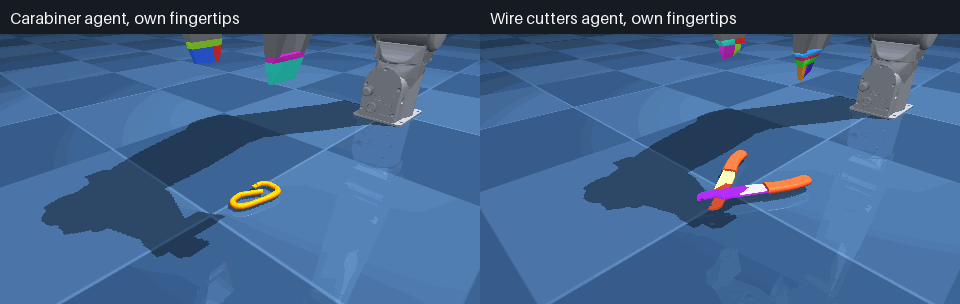

In [7]:
results = {}
with precomputed_decompositions(*bundles.values()):
    for tool, bundle in bundles.items():
        env, _ = make_tools_env(bundle.env_id, 1, device=DEVICE, seed=SEED, render_mode="rgb_array", noise=False)
        frame_tool(env, bundle.design)
        results[tool] = rollout(env, policies[tool], bundle.design, bundle.theta, bundle.mesh_bound_m,
                                seed=SEED, record=[0], record_every=2, frame_scale=4)
        env.close()

for tool, res in results.items():
    print(f"{TOOLS[tool]:12s} -> return: {res['returns'][0]:6.2f}, final articulation: {res['articulation'][0]:.2f}, "
          f"max lift: {res['max_lift_cm'][0]:.1f} cm")

clips = [results[tool]["frames"][0] for tool in TOOLS]
combined = [
    np.concatenate([label_frame(clip[min(i, len(clip) - 1)], f"{TOOLS[tool]} agent, own fingertips")
                    for tool, clip in zip(TOOLS, clips)], axis=1)
    for i in range(max(map(len, clips)))
]
save_gif(combined, RUNS_DIR / "nerotools_agents.gif")

Let's track the tool's joint opening, its height and the return over the episode:

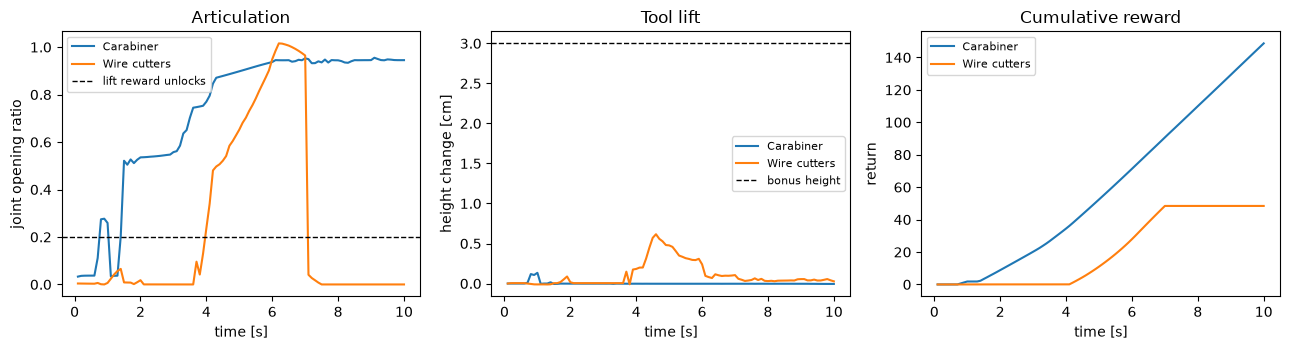

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for tool, res in results.items():
    traces = res["traces"]
    t = np.arange(1, len(traces["reward"]) + 1) * 0.1
    axes[0].plot(t, traces["articulation"][:, 0], label=TOOLS[tool])
    axes[1].plot(t, traces["lift_cm"][:, 0], label=TOOLS[tool])
    axes[2].plot(t, np.cumsum(traces["reward"][:, 0]), label=TOOLS[tool])
axes[0].axhline(0.2, color="k", ls="--", lw=1, label="lift reward unlocks")
axes[1].axhline(3.0, color="k", ls="--", lw=1, label="bonus height")
axes[0].set(xlabel="time [s]", ylabel="joint opening ratio", title="Articulation")
axes[1].set(xlabel="time [s]", ylabel="height change [cm]", title="Tool lift")
axes[2].set(xlabel="time [s]", ylabel="return", title="Cumulative reward")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

---

## 5. Fingertip Transplant

Each policy was co-adapted with its own fingertips. What happens if we give the carabiner agent the wire-cutter fingertips, and vice versa? For each tool, we run its policy with three fingertip sets: its own, the other tool's, and the base fingertips. The policy is always told which fingertips are installed (the base design is the all-zero vector).

Object pose noise has a large effect, so every fingertip set gets 4 worlds (one noise-free, one at 25% noise, two at full noise), batched into a single 12-world env per tool (~3 min in total).

In [ ]:
TIP_SETS = {
    "carabiner tips": (bundles["carabiner"].design, bundles["carabiner"].theta),
    "wire-cutter tips": (bundles["wirecutters"].design, bundles["wirecutters"].theta),
    "base tips": (bundles["carabiner"].base, np.zeros_like(bundles["carabiner"].theta)),
}
set_names = list(TIP_SETS)
WORLDS_PER_SET = 4
# World i gets set i % 3, so every set sees each noise level: in evaluation envs, the first quarter of
# the worlds is noise-free, the next quarter has 25% noise and the rest full noise.
world_sets = [set_names[i % len(set_names)] for i in range(len(set_names) * WORLDS_PER_SET)]

return_grid = np.zeros((len(TOOLS), len(set_names)))
artic_grid = np.zeros_like(return_grid)
swap_frames = {}
with precomputed_decompositions(*bundles.values()):
    for row, (tool, bundle) in enumerate(bundles.items()):
        env, _ = make_tools_env(bundle.env_id, len(world_sets), device=DEVICE, seed=SEED, render_mode="rgb_array")
        frame_tool(env, [TIP_SETS[name][0] for name in world_sets])
        res = rollout(env, policies[tool], [TIP_SETS[name][0] for name in world_sets],
                      np.stack([TIP_SETS[name][1] for name in world_sets]), bundle.mesh_bound_m,
                      seed=SEED, record=range(len(set_names)), record_every=2,
                      frame_scale=4)  # worlds 0-2: noise-free
        env.close()
        for col, name in enumerate(set_names):
            return_grid[row, col] = res["returns"][col::len(set_names)].mean()
            artic_grid[row, col] = res["articulation"][col::len(set_names)].mean()
            swap_frames[row, col] = res["frames"][col]
            print(f"{TOOLS[tool]:12s} agent with {name:16s} -> return: {return_grid[row, col]:6.2f}, "
                  f"articulation: {artic_grid[row, col]:.2f}")

fig, ax = plt.subplots(figsize=(7.8, 3.6))
im = ax.imshow(return_grid, cmap="RdYlGn")
ax.set(xticks=range(len(set_names)), xticklabels=set_names, yticks=range(len(TOOLS)),
       yticklabels=[f"{name} agent" for name in TOOLS.values()], xlabel="Installed fingertips",
       title=f"Fingertip transplant (mean over {WORLDS_PER_SET} worlds)")
for i in range(len(TOOLS)):
    for j in range(len(set_names)):
        ax.text(j, i, f"Return: {return_grid[i, j]:.1f}\nArticulation: {artic_grid[i, j]:.2f}",
                ha="center", va="center", fontsize=9.5, fontweight="bold")
fig.colorbar(im, ax=ax, label="Episode return")
plt.tight_layout()
plt.show()

[codesign-gym] make_vec('NeroGrasp-Tools-Carabiner', num_envs=12): instantiating
[codesign-gym] make_vec('NeroGrasp-Tools-Carabiner', num_envs=12): success


Let's watch the noise-free world of each pairing, in the same layout as the matrix above:

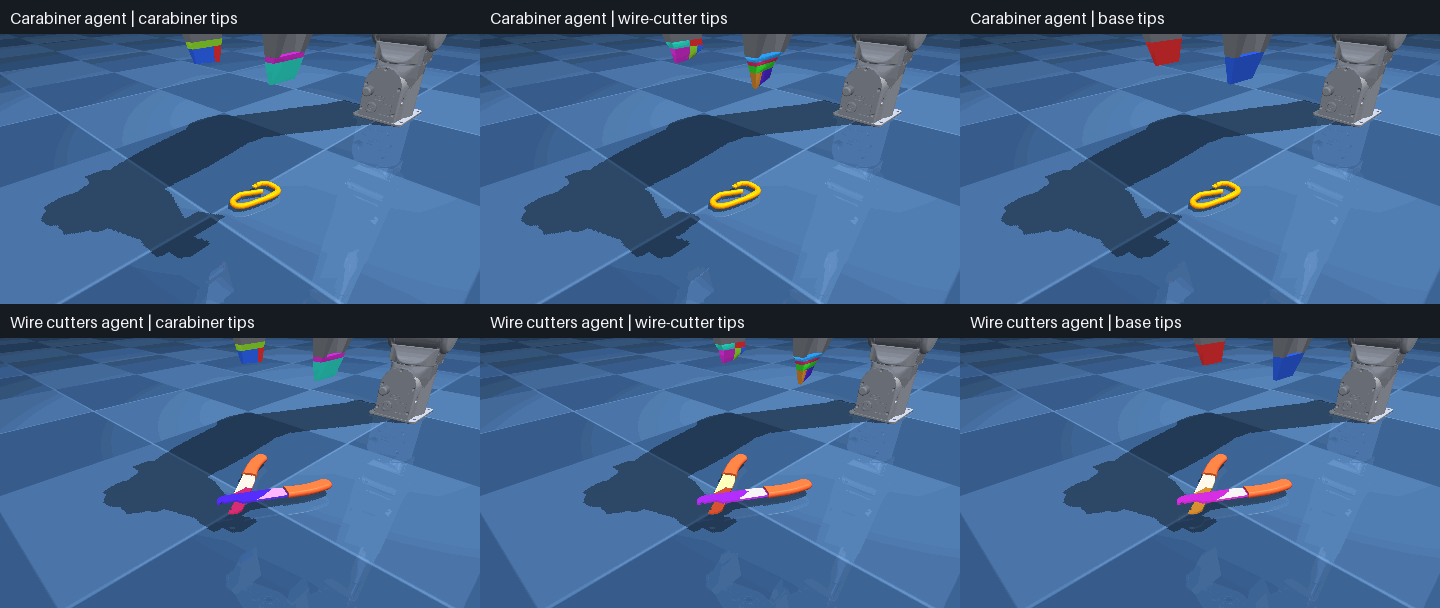

In [ ]:
n_frames = max(len(clip) for clip in swap_frames.values())
grid_frames = []
for k in range(n_frames):
    rows = []
    for i, tool_name in enumerate(TOOLS.values()):
        row = [label_frame(swap_frames[i, j][min(k, len(swap_frames[i, j]) - 1)], f"{tool_name} agent | {name}")
               for j, name in enumerate(set_names)]
        rows.append(np.concatenate(row, axis=1))
    grid_frames.append(np.concatenate(rows, axis=0))
save_gif(grid_frames, RUNS_DIR / "nerotools_transplant.gif")

---

## 6. How Were These Checkpoints Trained? (Reference CLI Commands)

Each agent trains thousands of MuJoCo Warp worlds on a single NVIDIA GPU for about an hour, and every fingertip candidate needs a GPU convex decomposition (`cuacd`), so we don't train here. Each bundle stores the exact `codesign-baselines` command that trained its checkpoint:

In [ ]:
for tool, bundle in bundles.items():
    print(f"# {TOOLS[tool]}\n{bundle.train_command}\n")

# Carabiner
python -m fasttd3_cmaes.gym_train \
  --env-id NeroGrasp-Tools-Carabiner \
  --env-kwargs '{"shape_parallel_workers": 8}' \
  --mesh-bound-m 0.005 \
  --use-cbd \
  --num-envs 512 \
  --seed 17 \
  --hours 1.0 \
  --batch-size 16384 \
  --warmup-steps 3000 \
  --search-frequency 500 \
  --population-size 64 \
  --cma-scale 1.5 \
  --evaluation-worlds 64 \
  --rejection-reward -10.0 \
  --replay-transitions 8000000 \
  --replay-memory-gb 24.0 \
  --actor-hidden-dim 256 \
  --critic-hidden-dim 512 \
  --weight-decay 0.0 \
  --num-steps 8 \
  --num-updates 4 \
  --v-min -15.0 \
  --v-max 400.0 \
  --num-atoms 201 \
  --std-min 0.05 \
  --std-max 0.5 \
  --policy-noise 0.05 \
  --no-obs-normalization \
  --output-dir exp_results/carabiner_seed_17

# Wire cutters
python -m fasttd3_cmaes.gym_train \
  --env-id NeroGrasp-Tools-WireCutters \
  --env-kwargs '{"shape_parallel_workers": 8}' \
  --mesh-bound-m 0.005 \
  --use-cbd \
  --num-envs 512 \
  --seed 6 \
  --hours 1.0 \
  --ba

`launch_nerotools_carabiner.sh` and `launch_nerotools_wirecutters.sh` in `codesign-baselines` queue several seeds of these commands across GPUs in `tmux` (`DRY_RUN=1` prints the commands without launching).

You can also inspect a checkpoint interactively on a desktop machine with a decomposition backend installed:
```bash
python ../../codesign-baselines/mujoco_visualiser.py nerotools_checkpoint_data/carabiner.pt
```